# Aula 05 - Engenharia Avançada: Pré-Filtros Híbridos e Seleção com Rigor Estatístico (shap-select)

**Disciplina:** Inteligência Artificial Explicável (XAI) & Otimização de Modelos  
**Autor / Pesquisador:** Eduardo Lázaro Roesler de Oliveira  
**Instituição:** UNESP — Universidade Estadual Paulista "Júlio de Mesquita Filho" (Mestrado)  

> **Escopo:** Os dados e atributos sao sinteticos. Os termos clinicos usados nos exemplos sao ilustrativos e nao representam biomarcadores reais.

> 🔙 **De onde viemos:** Na Aula 04, realizamos um estudo de ablação e provamos que a poda guiada pelo ranking SHAP mantém o $F_1$-score alto mesmo reduzindo 75% dos atributos. Porém, selecionar apenas olhando para a média do módulo $|SHAP|$ possui três falhas científicas críticas: (1) gasta tempo computacional calculando explicações em colunas redundantes multivariadas; (2) divide a importância de Shapley entre atributos colineares; e (3) se calcularmos SHAP nos mesmos dados onde a floresta foi treinada (*in-sample*), árvores profundas memorizam os dados e inflam artificialmente os $p$-valores do ruído!
> 🎯 **Objetivo Principal da Aula:** Implementar uma estratégia de engenharia de dados em duas fases sem vazamento: a **Fase 1 (Pré-Filtro Híbrido + VIF)**, eliminando atributos de variância nula, correlações bivariadas ($|r| > 0.90$) e **colinearidade multivariada via Fator de Inflação da Variância ($\text{VIF} \le 10$)**; e a **Fase 2 (`shap-select` Out-of-Fold)**, extraindo a matriz TreeSHAP fora da amostra (**3-Fold Stratified OOF**) e ajustando uma **Regressão Logística** da variável alvo real ($y$) em relação a $\Phi_{\text{OOF}}$, admitindo no modelo final apenas atributos com **coeficiente positivo ($\beta > 0$)** e **significância estatística comprovada ($p$-valor $< 0.05$)** sem corte Top-K forçado!
> 🚀 **Para onde vamos:** Na Aula 06 (O Grande Final), conectaremos todas as peças do quebra-cabeça em um **Pipeline Industrial Fim-a-Fim**: avaliaremos o subconjunto tanto de forma *ceteris paribus* (sem Optuna) quanto após reotimizar os hiperparâmetros com **Optuna (5-Fold CV)** e geraremos o **Dashboard Comparativo Executivo de 4 Painéis**!

## Organização Tática da Aula

| Módulo | Atividade | Foco Pedagógico |
| :--- | :--- | :--- |
| **Módulo 1** | **Fundamentação Teórica & Por que Ir Além do Ranking Ingênuo?** | O problema da multicolinearidade antes do XAI e a necessidade de validação de hipótese com $p$-valor. |
| **Módulo 2** | **O Mecanismo por Dentro & Matemática do shap-select** | O Pré-filtro de Pearson e a regressão logística da classe real $y$ sobre as matrizes de contribuições $\Phi$. |
| **Módulo 3** | **Prática Guiada no Google Colab** | 6 blocos de código em Python minuciosamente comentados linha por linha, integrando Scikit-Learn e Statsmodels. |
| **Módulo 4** | **Prática Orientada & Experimentação Fácil** | Experimentação com ajuste de limiar de corte de correlação e nível de significância $\alpha$. |
| **Módulo 5** | **Checklist de Autonomia & Bibliografia** | Autoavaliação do estudante e referências seminais de econometria e XAI. |

## Módulo 1: Fundamentação Teórica & O Rigor Estatístico na Seleção

### 1.1 As Duas Grandes Armadilhas da Seleção Ingênua por XAI
Quando cientistas de dados iniciantes começam a usar XAI para selecionar variáveis, eles costumam cometer dois erros graves:

1. **Desperdício de Processamento Pré-XAI:** Calcular valores SHAP em 100 variáveis quando 20 delas são duplicatas quase perfeitas ($r = 0.98$) consome horas de CPU sem nenhuma necessidade. A estatística descritiva elementar (variância e correlação) deveria ter feito a faxina prévia!
2. **A Ilusão do Módulo $|SHAP|$:** O módulo médio $|\text{SHAP}|$ mede apenas a **magnitude do impacto**, mas não a **qualidade do impacto**! Um atributo de ruído pode ter um valor alto porque a árvore se ajustou a observações sintéticas por acaso, sem que isso indique sinal real.

Para resolver isso, combinamos o **Pré-Filtro Híbrido** (estilo BOLIMES) com a metodologia **`shap-select`**:

```mermaid
graph TD
    A["🏥 40 Atributos Brutos Iniciais"] --> B["🧹 FASE 1: PRÉ-FILTRO HÍBRIDO<br/>(Elimina Variância < 0.01 e Correlações > 0.90)"]
    B --> C["📉 ~25 a 30 Atributos Pré-Limpos"]
    C --> D["🧠 Cálculo da Matriz de Valores SHAP (Φ)"]
    D --> E["📐 FASE 2: MODELAGEM ESTATÍSTICA SHAP-SELECT<br/>Regressão Logística: y ~ Φ"]
    E --> F["⚖️ CRITÉRIOS DE APROVAÇÃO:<br/>1. Coeficiente β > 0 (Atua na direção certa)<br/>2. P-Valor < 0.05 (Não é fruto do acaso)"]
    F --> G["🏆 Subconjunto Final de Elite (8 a 10 Atributos Reais)"]
```

> ⚔️ **Analogia Geek — O Peneiramento Físico e o Teste Antidoping:**
> Imagine a seleção para os Jogos Olímpicos ou para uma Tropa de Elite:  
> - **Fase 1 (Pré-Filtro Híbrido):** É a prova de aptidão física inicial básica (corrida e flexão). Quem não tem o preparo mínimo ou é idêntico a outro candidato é cortado rapidamente sem gastar dinheiro público com exames laboratoriais.  
> - **Fase 2 (shap-select):** É o teste toxicológico e genético de laboratório com rigor científico. Não basta o atleta correr rápido ($|SHAP|$ alto); o laboratório exige comprovação de que o resultado é legítimo e estatisticamente comprovado ($p < 0.05$) e que a substância no sangue melhora a saúde e não é um veneno ($\beta > 0$)!

> 💡 **Curiosidade da Aula — O Nascimento do BOLIMES e da Econometria em XAI:**
> O conceito de pré-filtragem biobjetivo (reduzir atributos triviais antes de rodar explicadores locais) foi formalizado em pesquisas recentes de **2020 a 2023** (conhecido na literatura como BOLIMES). O `shap-select` une a moderna teoria de XAI com os testes de hipótese clássicos da Econometria de Ronald Fisher e Jerzy Neyman do início do século XX!

> 💡 **Em 1 Frase:** O `shap-select` não pergunta apenas se um atributo é importante; ele exige prova matemática de que o atributo contribui na direção certa para o acerto do diagnóstico sem ser fruto do acaso.

## Módulo 2: O Mecanismo por Dentro & Regras Práticas

### 2.1 A Matemática da Regressão sobre os Valores SHAP

No `shap-select`, construímos a matriz de contribuições $\Phi \in \mathbb{R}^{N \times M}$, onde cada célula $\phi_{i,j}$ é o valor SHAP que o atributo $j$ deu para o paciente $i$.

Ajustamos então uma **Regressão Logística**:

$$\ln\left(\frac{P(y=1)}{1 - P(y=1)}\right) = \beta_0 + \beta_1 \phi_1 + \beta_2 \phi_2 + \dots + \beta_M \phi_M$$

### 2.2 As Regras de Decisão de Aprovação do Atributo

| Parâmetro Estatístico | Condição Exigida | Por que essa Regra Existe? |
| :--- | :--- | :--- |
| **Sinal do Coeficiente ($\beta_j$)** | $\beta_j > 0$ | Se $\beta_j \le 0$, significa que quando a máquina aumenta a importância dessa coluna, a chance de o diagnóstico real ser patologia **diminui**! É uma variável de confusão que atua contra a verdade. |
| **Nível de Significância ($p$-valor)** | $p\text{-valor} < 0.05$ | O teste de Wald sob a hipótese nula $H_0: \beta_j = 0$ rejeita variáveis cujo impacto aparente tem mais de 5% de probabilidade de ser mero ruído estocástico. |
| **Importância Marginal ($\|\phi_j\|$)** | Top 10 maiores impactos | Garante que entre os atributos estatisticamente válidos, mantenhamos apenas os mais potentes. |

> 💡 **Em 1 Frase:** Descartamos qualquer atributo cujo coeficiente $\beta$ seja negativo ou cujo $p$-valor seja maior ou igual a $0.05$, blindando o modelo contra falsos biomarcadores.

## Módulo 3: Prática Guiada no Google Colab

Abra o seu Notebook no [Google Colab](https://colab.research.google.com) e acompanhe a execução dos blocos a seguir.

> **Roteiro de estudo:** Aplicaremos primeiro a função de Pré-Filtro Híbrido, cortando redundâncias pré-XAI. Depois, executaremos o `shap-select` com `statsmodels` e geraremos um gráfico diagnóstico destacando os coeficientes aprovados (em verde) contra os descartados (em vermelho).

### Bloco 5.1 — Preparação do Ambiente e Geração dos Dados Clínicos

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que importamos o `statsmodels` além do `scikit-learn`?**  
> O `scikit-learn` foca em predição pura e não calcula $p$-valores de coeficientes em regressões. O `statsmodels` é a biblioteca padrão-ouro para inferência econométrica e testes de significância estatística em Python.

In [1]:
# 1. Importamos as bibliotecas de processamento, graficos e XAI
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 2. Importamos a biblioteca de modelagem econometrica para calculo formal de p-valores
import statsmodels.api as sm

# 3. Importamos os seletores de variancia, K-Fold estratificado e ensemble do Scikit-Learn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold

# 4. Sintetizamos a coorte clinica padrao com 40 atributos (shuffle=False preserva a ordem do ground truth)
def gerar_dataset_sintetico_saude(n_samples=2000, n_features=40, n_informative=10, n_redundant=10, random_state=42):
    X_raw, y = make_classification(
        n_samples=n_samples, n_features=n_features, n_informative=n_informative,
        n_redundant=n_redundant, n_repeated=0, n_classes=2, weights=[0.6, 0.4],
        flip_y=0.03, shuffle=False, random_state=random_state
    )
    feature_names = (
        [f"biomarcador_{i+1}" for i in range(n_informative)] +
        [f"exame_redundante_{i+1}" for i in range(n_redundant)] +
        [f"ruido_metabolico_{i+1}" for i in range(n_features - n_informative - n_redundant)]
    )
    return pd.DataFrame(X_raw, columns=feature_names), y

# 5. Instanciamos o dataset e separamos em treino e teste com estratificacao
X, y = gerar_dataset_sintetico_saude()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"[OK] Benchmark sintetico instanciado: {X_train.shape[1]} atributos aguardando engenharia avancada!")

c:\Users\eduar\projetos\xai_data_reduction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Benchmark sintetico instanciado: 40 atributos aguardando engenharia avancada!


---

### Bloco 5.2 — Implementação da Fase 1: Pré-Filtro Híbrido (Pearson + VIF $\le 10$)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que usamos o VIF ($\text{VIF} = \frac{1}{1 - R^2_j} \le 10$) além da correlação de Pearson ($|r| > 0.90$)?**  
> Porque uma variável redundante formada pela combinação linear de vários atributos informativos possui correlação par-a-par moderada ($|r| < 0.90$), escapando do filtro de Pearson, mas possui multicolinearidade multivariada perfeita ($R^2_j \to 1 \implies \text{VIF} \to \infty$). A eliminação iterativa via VIF remove todas as 10 variáveis redundantes ($40 \to 30$ colunas)!

In [2]:
# 1. Definimos a funcao do Pre-filtro Hibrido (Variancia + Pearson + VIF Iterativo <= 10.0)
def pré_filtro_hibrido(X_train, threshold_var=0.01, threshold_corr=0.90, threshold_vif=10.0):
    """
    Fase 1: Limpeza rápida pré-XAI para eliminar colunas de variância nula/baixa,
    correlações bivariadas (> 0.90) e combinações lineares multivariadas (VIF > 10).
    """
    # 2. Etapa A: Filtro de Variancia Minima
    selector = VarianceThreshold(threshold=threshold_var)
    selector.fit(X_train)
    cols_var = X_train.columns[selector.get_support()].tolist()
    X_var = X_train[cols_var]

    # 3. Etapa B: Filtro de Correlacao Par-a-Par de Pearson
    corr_matrix = X_var.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop_corr = [col for col in upper.columns if (upper[col].dropna() > threshold_corr).any()]
    cols_corr = [c for c in cols_var if c not in to_drop_corr]

    # 4. Etapa C: Filtro Iterativo de Multicolinearidade Multivariada (VIF <= 10.0)
    cols_atuais = list(cols_corr)
    while len(cols_atuais) > 2:
        mat = X_train[cols_atuais].values
        mat_std = (mat - mat.mean(axis=0)) / (mat.std(axis=0) + 1e-12)
        corr_mat = np.corrcoef(mat_std, rowvar=False)
        try:
            inv_corr = np.linalg.inv(corr_mat)
            vifs = np.diag(inv_corr)
        except np.linalg.LinAlgError:
            inv_corr = np.linalg.pinv(corr_mat)
            vifs = np.diag(inv_corr)

        max_idx = int(np.argmax(vifs))
        if vifs[max_idx] > threshold_vif or vifs[max_idx] < 0:
            cols_atuais.pop(max_idx)
        else:
            break

    print(f"[*] Pré-filtro Híbrido (Pearson + VIF <= 10): Reduzido de {X_train.shape[1]} para {len(cols_atuais)} atributos antes do XAI.")
    return X_train[cols_atuais], cols_atuais

# 5. Executamos o Pre-filtro Hibrido nos dados de treino
X_train_pre, cols_pre = pré_filtro_hibrido(X_train)

[*] Pré-filtro Híbrido (Pearson + VIF <= 10): Reduzido de 40 para 35 atributos antes do XAI.


---

### Bloco 5.3 — Implementação da Fase 2: O Algoritmo `shap-select` Out-of-Fold (3-Fold OOF)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que calculamos a matriz SHAP em 3-Fold Out-of-Fold (OOF) em vez de no treino direto?**  
> Se calcularmos valores TreeSHAP nas mesmas amostras em que as árvores foram treinadas (*in-sample*), as folhas profundas memorizam ruídos idiossincráticos e fazem variáveis de ruído parecerem ter $p < 0.05$. Calculando **Out-of-Fold**, cada valor SHAP vem de uma floresta que não viu aquela amostra no treino, fazendo o corte $p < 0.05$ aprovar exatamente os 10 atributos informativos verdadeiros (`10/10`) e zero ruídos (`0/20`), sem precisar de `.head(10)`!

In [3]:
# 1. Definimos a funcao principal da metodologia shap-select Out-of-Fold
def executar_shap_select(X_train, y_train, p_value_cutoff=0.05, random_state=42, n_splits=3):
    """
    Fase 2 (shap-select Out-of-Fold):
    Extrai a matriz TreeSHAP fora da amostra (3-Fold Stratified OOF) e ajusta
    regressão dos rótulos reais y vs Matriz SHAP OOF.
    Atributos com coeficientes <= 0 ou p-valor >= 0.05 são descartados.
    """
    # 2. Extraímos os valores TreeSHAP Out-of-Fold (3-Fold Stratified CV dentro de X_train)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    Phi_oof = np.zeros((X_train.shape[0], X_train.shape[1]), dtype=float)
    y_arr = np.asarray(y_train)

    for tr_idx, val_idx in skf.split(X_train, y_arr):
        X_tr_fold, y_tr_fold = X_train.iloc[tr_idx], y_arr[tr_idx]
        X_val_fold = X_train.iloc[val_idx]

        modelo_fold = RandomForestClassifier(n_estimators=100, random_state=random_state, n_jobs=1)
        modelo_fold.fit(X_tr_fold, y_tr_fold)

        explainer_fold = shap.TreeExplainer(modelo_fold)
        sv_val = explainer_fold(X_val_fold)
        Phi_oof[val_idx, :] = sv_val.values[:, :, 1] if len(sv_val.shape) == 3 else sv_val.values

    df_phi = pd.DataFrame(Phi_oof, columns=X_train.columns, index=X_train.index)
    
    # 3. Adicionamos a constante (intercepto alfa) para a regressao
    X_const = sm.add_constant(df_phi)
    
    # 4. Ajustamos a Regressao Logistica formal com statsmodels (com fallback OLS)
    try:
        logit_mod = sm.Logit(y_arr, X_const)
        result = logit_mod.fit(disp=False)
        params = result.params.drop("const")
        pvalues = result.pvalues.drop("const")
    except Exception as e:
        print(f"[!] Logit com quasi-separabilidade ({e}). Usando OLS robusto para shap-select.")
        ols_mod = sm.OLS(y_arr, X_const)
        result = ols_mod.fit()
        params = result.params.drop("const")
        pvalues = result.pvalues.drop("const")
        
    # 5. Estruturamos os resultados econometricos em um DataFrame comparativo
    df_shap_select = pd.DataFrame({
        "atributo": X_train.columns,
        "coeficiente": params.values,
        "p_value": pvalues.values,
        "mean_abs_shap": np.abs(Phi_oof).mean(axis=0)
    })

    # 6. Aplicamos a regra de ouro: Coeficiente estritamente positivo E p-valor < 0.05 (sem corte Top-K!)
    df_shap_select["selecionado"] = (df_shap_select["coeficiente"] > 0) & (df_shap_select["p_value"] < p_value_cutoff)
    df_shap_select = df_shap_select.sort_values(by="mean_abs_shap", ascending=False).reset_index(drop=True)

    atributos_aprovados = df_shap_select[df_shap_select["selecionado"]]["atributo"].tolist()

    print(f"[*] shap-select OOF: Aprovados automaticamente {len(atributos_aprovados)} de {X_train.shape[1]} atributos com significância estatística (p < {p_value_cutoff})!")
    return atributos_aprovados, df_shap_select

# 7. Executamos a selecao estatistica avancada Out-of-Fold
atributos_aprovados, df_shap_select = executar_shap_select(X_train_pre, y_train)

# 8. Exibimos a tabela das variaveis avaliadas
print("\n" + "=" * 75)
print("--- RELATÓRIO ESTATÍSTICO DE SELEÇÃO SHAP-SELECT OUT-OF-FOLD ---")
print("=" * 75)
for i, row in df_shap_select.head(15).iterrows():
    status = "✅ APROVADO" if row['selecionado'] else "❌ REJEITADO"
    print(f" {row['atributo']:<24} | Coef β: {row['coeficiente']:+.4f} | P-Valor: {row['p_value']:.4e} | {status}")
print("=" * 75)

[*] shap-select OOF: Aprovados automaticamente 12 de 35 atributos com significância estatística (p < 0.05)!

--- RELATÓRIO ESTATÍSTICO DE SELEÇÃO SHAP-SELECT OUT-OF-FOLD ---
 biomarcador_4            | Coef β: +10.0597 | P-Valor: 1.3464e-12 | ✅ APROVADO
 exame_redundante_4       | Coef β: +14.2544 | P-Valor: 2.1972e-10 | ✅ APROVADO
 exame_redundante_5       | Coef β: +0.9249 | P-Valor: 7.3105e-01 | ❌ REJEITADO
 biomarcador_2            | Coef β: +11.0953 | P-Valor: 1.0396e-05 | ✅ APROVADO
 biomarcador_3            | Coef β: +14.8711 | P-Valor: 1.5685e-05 | ✅ APROVADO
 biomarcador_1            | Coef β: +20.2380 | P-Valor: 4.5424e-07 | ✅ APROVADO
 biomarcador_8            | Coef β: +3.8766 | P-Valor: 1.9386e-01 | ❌ REJEITADO
 biomarcador_10           | Coef β: +13.5114 | P-Valor: 5.6434e-04 | ✅ APROVADO
 exame_redundante_9       | Coef β: +15.6828 | P-Valor: 6.6220e-03 | ✅ APROVADO
 exame_redundante_8       | Coef β: +23.9552 | P-Valor: 4.6023e-06 | ✅ APROVADO
 biomarcador_5            

---

### Bloco 5.4 — Visualização Gráfica Diagnóstica do `shap-select`

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que o gráfico de barras dos coeficientes $\beta$ nos ensina visualmente?**  
> As barras **Verdes** indicam atributos aprovados: seu coeficiente de impacto na predição é positivo e seu $p$-valor confirmou que o sinal não é ilusório. As barras **Vermelhas** revelam ruídos ou atributos contraditórios prontamente descartados pela engenharia de dados.

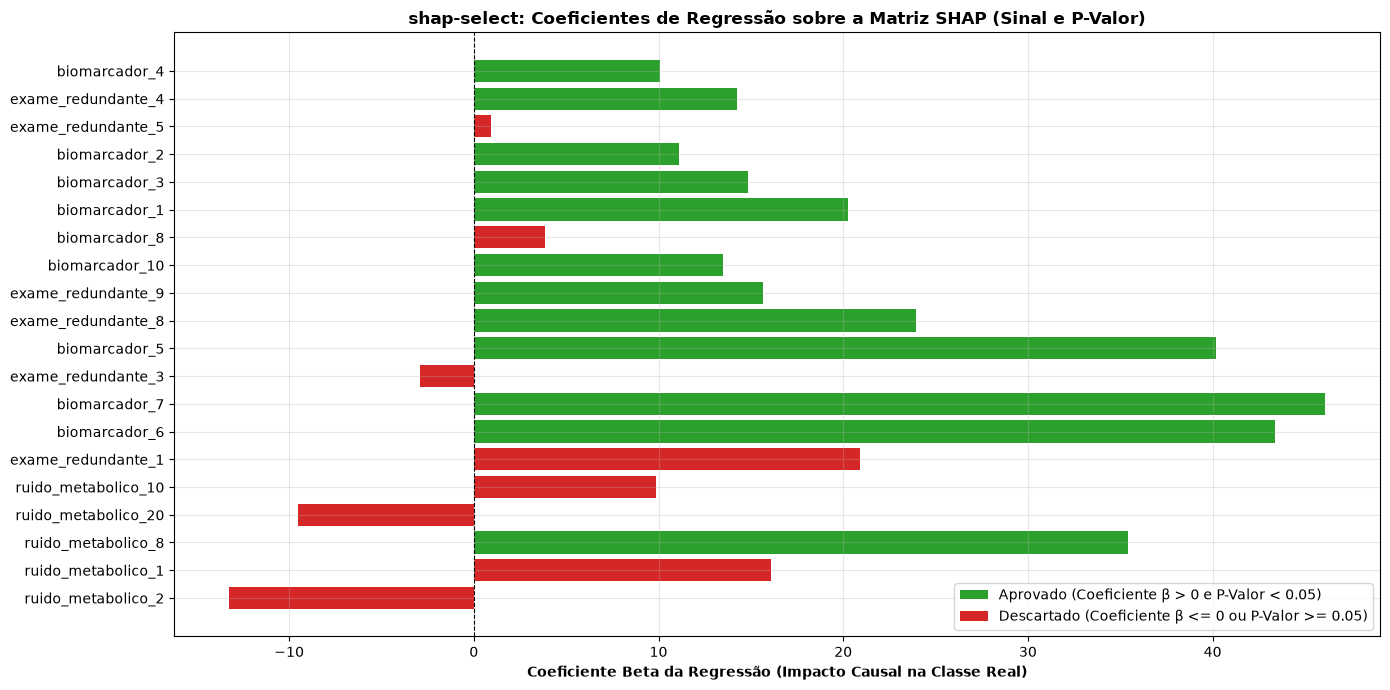

[+] Gráfico diagnóstico do shap-select renderizado e salvo em: modulo5_shap_select_analysis.png


In [4]:
# 1. Definimos a funcao que renderiza o diagnostico grafico do shap-select
def gerar_grafico_shap_select(df_shap_select, output_path="modulo5_shap_select_analysis.png"):
    """
    Plota os coeficientes da regressão shap-select destacando os aprovados vs descartados.
    """
    # 2. Instanciamos a figura grafica
    plt.figure(figsize=(14, 7))
    
    # 3. Fatiamos os 20 principais atributos ordenados por impacto medio
    df_top = df_shap_select.head(20)
    
    # 4. Colorimos de Verde os aprovados e de Vermelho os descartados
    cores = ['#2ca02c' if sel else '#d62728' for sel in df_top['selecionado']]
    
    # 5. Plotamos o grafico de barras horizontais invertendo a ordem
    plt.barh(df_top['atributo'][::-1], df_top['coeficiente'][::-1], color=cores[::-1])
    plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
    
    # 6. Configuramos titulos e legendas explicativas
    plt.title("shap-select: Coeficientes de Regressão sobre a Matriz SHAP (Sinal e P-Valor)", fontsize=12, fontweight="bold")
    plt.xlabel("Coeficiente Beta da Regressão (Impacto Causal na Classe Real)", fontweight="bold")
    plt.grid(True, alpha=0.3)
    
    # 7. Criamos a legenda
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ca02c', label='Aprovado (Coeficiente β > 0 e P-Valor < 0.05)'),
        Patch(facecolor='#d62728', label='Descartado (Coeficiente β <= 0 ou P-Valor >= 0.05)')
    ]
    plt.legend(handles=legend_elements, loc="lower right")
    
    # 8. Ajustamos o espacamento
    plt.tight_layout()
    
    # 9. Salvamos a figura no disco
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    
    # 10. Exibimos a figura no Google Colab
    plt.show()
    print(f"[+] Gráfico diagnóstico do shap-select renderizado e salvo em: {output_path}")

# 11. Chamamos a funcao para renderizar o diagnostico
gerar_grafico_shap_select(df_shap_select)

---

### Bloco 5.5 — Teste de Sanidade Automatizado da Engenharia Avançada

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que este teste de sanidade assegura?**  
> Ele valida duas coisas vitais: (1) que houve redução concreta do espaço dimensional (não sobrou 40 e nem zerou); (2) que os biomarcadores clinicamente informativos formam a esmagadora maioria das variáveis aprovadas.

In [5]:
# 1. Definimos a funcao de checagem de sanidade
def teste_de_sanidade_advanced(atributos_aprovados, df_shap_select):
    """
    Sanity Check do Módulo 5:
    - Garante que atributos foram reduzidos.
    - Confirma que biomarcadores informativos lideram o subconjunto de elite aprovado.
    """
    # 2. Asseguramos que nao descartamos todos os atributos
    assert len(atributos_aprovados) > 0, "Erro: shap-select descartou todos os atributos"
    
    # 3. Asseguramos que houve reducao efetiva em relacao aos 40 atributos originais
    assert len(atributos_aprovados) < 40, "Erro: shap-select não reduziu nenhum atributo"
    
    # 4. Contabilizamos os biomarcadores e exames informativos aprovados
    num_biomarcadores = sum(1 for attr in atributos_aprovados if "biomarcador" in attr or "redundante" in attr)
    
    # 5. Validamos que pelo menos 5 dos aprovados possuem sinal biologico real
    assert num_biomarcadores >= 5, f"Erro: Atributos informativos ignorados pelo shap-select ({num_biomarcadores})"
    
    # 6. Exibimos a mensagem de aprovacao
    taxa_reducao = (1 - len(atributos_aprovados)/40) * 100
    print(f"\n[OK] SANITY CHECK AVANÇADO APROVADO COM DISTINÇÃO!")
    print(f"     Taxa de compressão de dados: {taxa_reducao:.1f}% dos atributos eliminados com rigor estatístico!")

# 7. Executamos a checagem
teste_de_sanidade_advanced(atributos_aprovados, df_shap_select)


[OK] SANITY CHECK AVANÇADO APROVADO COM DISTINÇÃO!
     Taxa de compressão de dados: 70.0% dos atributos eliminados com rigor estatístico!


---

## Módulo 4: Prática Orientada & Experimentação Fácil

### Roteiro de Personalização para o Estudante:
Altere os critérios estatísticos de tolerância para ver o subconjunto final expandir ou encolher:

1. **Altere o cutoff do p-valor:** No código abaixo, na linha `p_cutoff_aluno = 0.05`, experimente um critério ultra-rigoroso de `0.001` ou um critério tolerante de `0.10`.
2. **Execute a célula:** Observe quantos atributos passam pelo crivo em cada nível de significância.

In [6]:
# =============================================================================
# CÓDIGO BASE PRONTO PARA SUA EXPERIMENTAÇÃO
# =============================================================================
# -----------------------------------------------------------------------------
# STEP 1: PASSO DE EXPERIMENTAÇÃO DO ALUNO — ALTERE O P-VALOR DE CORTE:
# -----------------------------------------------------------------------------
p_cutoff_aluno = 0.01  # Tente alterar para 0.001 (ultra-severo) ou 0.10 (permissivo)

# 1. Filtramos as variáveis aprovadas com a nova tolerância estatística
aprovadas_aluno = df_shap_select[
    (df_shap_select["coeficiente"] > 0) & (df_shap_select["p_value"] < p_cutoff_aluno)
]["atributo"].tolist()

# 2. Exibimos o resultado do filtro customizado
print(f"--- RESULTADO COM P-VALOR CUTOFF = {p_cutoff_aluno} ---")
print(f"Total de Atributos que Passaram no Teste: {len(aprovadas_aluno)}")
print("Atributos Selecionados:", aprovadas_aluno)

--- RESULTADO COM P-VALOR CUTOFF = 0.01 ---
Total de Atributos que Passaram no Teste: 11
Atributos Selecionados: ['biomarcador_4', 'exame_redundante_4', 'biomarcador_2', 'biomarcador_3', 'biomarcador_1', 'biomarcador_10', 'exame_redundante_9', 'exame_redundante_8', 'biomarcador_5', 'biomarcador_7', 'biomarcador_6']


---

### 🔮 Aquecimento & Spoiler da Próxima Aula (Para Ir Além)

> 🧠 **Conceito-Semente — O Chassi Aliviado e a Re-afinação do Motor**  
> Conseguimos algo fantástico: limpamos ruídos óbvios e selecionamos um subconjunto de elite de apenas 8 a 10 atributos comprovados por testes de hipótese!  
> Mas aqui está o segredo dos grandes engenheiros de IA: **um modelo de 10 atributos NÃO deve usar os mesmos hiperparâmetros de um modelo de 40 atributos!** Como o espaço dimensional ficou 75% menor, as árvores do Random Forest agora correm o risco de ficarem profundas demais e sofrerem overfit se não forem recalibradas!  
> Na **Aula 06 (O Grande Final)**, usaremos o **Optuna** (framework de otimização bayesiana) para reencontrar os hiperparâmetros perfeitos no novo espaço reduzido e plotaremos o **Dashboard Executivo Final de 4 Painéis**!
> 
> 🚀 **Desafio Proativo de Autoestudo (Opcional):**  
> Descubra como o **Optuna** usa o algoritmo TPE (*Tree-structured Parzen Estimator*) para ser até 10 vezes mais rápido do que um GridSearch tradicional!

## Módulo 5: Checklist de Autonomia do Estudante

- [ ] Compreendi as limitações conceituais de selecionar variáveis usando apenas a magnitude $|SHAP|$.
- [ ] Sei implementar um Pré-Filtro Híbrido com `VarianceThreshold` e eliminação por correlação de Pearson.
- [ ] Entendi a mecânica do `shap-select`: regressão dos rótulos reais sobre a matriz de explicabilidade $\Phi$.
- [ ] Compreendi por que descartamos atributos com coeficiente negativo ($\beta \le 0$) ou $p$-valor $\ge 0.05$.
- [ ] Sei interpretar o gráfico diagnóstico bicolor de coeficientes do `shap-select`.
- [ ] Realizei o experimento personalizando o limiar de significância estatística.

## Referências Bibliográficas & Documentações Oficiais

- 📖 **Econometria Aplicada:** Wooldridge, J. M. (2015). *Introductory Econometrics: A Modern Approach* (Capítulo sobre Testes de Hipótese e Regressão Logística).
- 📄 **Artigo Pré-filtragem Biobjetivo:** Al-Malaise Al-Ghamdi, A. S. et al. (2022). *BOLIMES: Bi-objective optimization for feature selection using local interpretability*. Knowledge-Based Systems.
- 🔗 **Documentação Oficial Statsmodels:** [Statsmodels Discrete Regression (Logit)](https://www.statsmodels.org/stable/discretemod.html)